# Offline navigation: BC, TD3 and BCQ

This notebook follows one real transition from `data/mixed.npz` through a BCQ update.
Saved outputs were computed on CPU. Short demo runs are smoke tests, not final results.

## 1. Google Colab setup

Run the next cell in Colab to clone the project and install dependencies.
Locally, it prints the working directory. Select Runtime > Change runtime type > GPU
for GPU training. Cloning includes local changes only after they are published.

In [1]:
import importlib.util
import os
from pathlib import Path
import subprocess
import sys

if importlib.util.find_spec("google.colab") is not None:
    project = Path("/content/RL_Project")
    if not project.exists():
        subprocess.run([
            "git", "clone", "https://github.com/Andreyfdp/RL_Project.git", str(project)
        ], check=True)
    os.chdir(project)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
print("Project:", Path.cwd())

Project: C:\Users\ksvibe\RL_Project


In [2]:
%matplotlib inline
import json
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from IPython.display import HTML, Image, Markdown, display
from matplotlib.animation import FuncAnimation
from matplotlib.patches import Rectangle

from bcq import BCQ
from config import MODEL_PATH, OBSTACLES, RESULTS_DIR
from dataset import OfflineDataset
from train import build_parser, evaluate, isolated_rng, make_agent, set_seed, train

torch.set_num_threads(1)
set_seed(0)
dataset = OfflineDataset("data/mixed.npz", device="cpu")
print("Transitions:", len(dataset))
print("PyTorch:", torch.__version__, "CUDA:", torch.cuda.is_available())

Transitions: 24598
PyTorch: 2.12.0+cpu CUDA: False


## 2. One real transition

The state is `[x, y, goal_x - x, goal_y - y]`.
`done` marks a goal or collision. Time limits are stored separately in `timeouts`
and keep the Bellman bootstrap. This example updates one transition; training uses batch=256.

In [3]:
index = 0
batch = tuple(t[index:index + 1].clone() for t in (
    dataset.states, dataset.actions, dataset.rewards, dataset.next_states, dataset.dones
))
states, actions, rewards, next_states, dones = batch
agent = BCQ(4, 2, phi=0.05, device="cpu")
print("Dataset index:", index)
for name, value in zip(("s", "a", "r", "s_next", "done"), batch):
    print(name, "=", value.numpy().round(5))
with np.load("data/mixed.npz") as raw:
    print("timeout =", raw["timeouts"][index] if "timeouts" in raw else "not provided")

Dataset index: 0
s = [[1.16437 0.96333 7.83563 8.03667]]
a = [[0.3861  0.94114]]
r = [[1.62687]]
s_next = [[1.29951 1.29273 7.70049 7.70727]]
done = [[0.]]
timeout = [0.]


## 3. VAE: encode, sample, decode and update

$z=\mu+\sigma\epsilon$, $L_{VAE}=MSE(\hat a,a)+0.5 KL$.
Use the same $\epsilon$ and latent probe before and after the update to isolate
parameter changes from sampling noise.

In [4]:
epsilon = torch.randn(1, agent.vae.latent_dim)
probe_z = torch.randn_like(epsilon).clamp(-0.5, 0.5)
mean, log_std = agent.vae.encode(states, actions)
std = log_std.exp()
reconstructed = agent.vae.decode(states, mean + std * epsilon)
reconstruction_loss = F.mse_loss(reconstructed, actions)
kl = -0.5 * torch.mean(1 + torch.log(std.square() + 1e-8) - mean.square() - std.square())
vae_loss = reconstruction_loss + 0.5 * kl
reconstruction_before = reconstructed.detach().clone()
with torch.no_grad():
    candidate_before = agent.vae.decode(states, probe_z)
agent.vae_optimizer.zero_grad()
vae_loss.backward()
agent.vae_optimizer.step()
with torch.no_grad():
    mean_after, log_std_after = agent.vae.encode(states, actions)
    reconstruction_after = agent.vae.decode(states, mean_after + log_std_after.exp() * epsilon)
    candidate = agent.vae.decode(states, probe_z)
print("mu:", mean.detach().numpy().round(5), "std:", std.detach().numpy().round(5))
print(f"reconstruction loss={reconstruction_loss.item():.6f}; KL={kl.item():.6f}; total={vae_loss.item():.6f}")
print("Real action:", actions.numpy().round(5))
print("Reconstruction before:", reconstruction_before.numpy().round(5))
print("Reconstruction after: ", reconstruction_after.numpy().round(5))
print("Fixed latent candidate before/after:", candidate_before.numpy(), candidate.numpy())

mu: [[ 0.2404  -0.74124  0.32712 -0.08393]] std: [[0.58075 0.57863 0.81997 0.45805]]
reconstruction loss=1.192704; KL=0.301888; total=1.343648
Real action: [[0.3861  0.94114]]
Reconstruction before: [[-0.38442 -0.39741]]
Reconstruction after:  [[0.21733 0.51078]]
Fixed latent candidate before/after: [[-0.23907784 -0.40425003]] [[0.38322437 0.46909344]]


## 4. Perturbation and twin Q estimates

$\tilde a=clip(a_{VAE}+\Phi\tanh(\xi(s,a_{VAE})), -1,1)$.
Each action correction is bounded by Phi=0.05. Both critics then score the action.

In [5]:
with torch.no_grad():
    perturbed_before = agent.actor(states, candidate)
    candidate_q1, candidate_q2 = agent.critic(states, perturbed_before)
print("VAE action:", candidate.numpy().round(5))
print("Perturbed action:", perturbed_before.numpy().round(5))
print("Correction:", (perturbed_before - candidate).numpy().round(5))
print("Q1, Q2:", candidate_q1.item(), candidate_q2.item())

VAE action: [[0.38322 0.46909]]
Perturbed action: [[0.37091 0.44387]]
Correction: [[-0.01232 -0.02523]]
Q1, Q2: -0.02063516527414322 -0.9000070691108704


## 5. Target y from ten next-state candidates

$Q_{mix}=0.75\min(Q_1',Q_2')+0.25\max(Q_1',Q_2')$,
$y=r+\gamma(1-done)\max_i Q_{mix}(s',a_i')$.
Compute the target without gradients after the VAE update, as in `BCQ.train`.

In [6]:
with torch.no_grad():
    repeated_next = next_states.repeat_interleave(10, dim=0)
    next_candidates = agent.vae.decode(repeated_next)
    next_actions = agent.actor_target(repeated_next, next_candidates)
    target_q1, target_q2 = agent.critic_target(repeated_next, next_actions)
    mixed_q = 0.75 * torch.minimum(target_q1, target_q2) + 0.25 * torch.maximum(target_q1, target_q2)
    best_q = mixed_q.view(1, 10).max(dim=1, keepdim=True).values
    target_y = rewards + (1 - dones) * agent.gamma * best_q
print("i      VAE a                   perturbed a               Q1        Q2       Qmix")
for i in range(10):
    print(f"{i}  {next_candidates[i].numpy().round(4)}  {next_actions[i].numpy().round(4)}  "
          f"{target_q1[i].item():9.5f} {target_q2[i].item():9.5f} {mixed_q[i].item():9.5f}")
print(f"y = {rewards.item():.6f} + {agent.gamma} * (1 - {dones.item():.0f}) * {best_q.item():.6f} = {target_y.item():.6f}")

i      VAE a                   perturbed a               Q1        Q2       Qmix
0  [0.3562 0.4338]  [0.3436 0.4089]   -0.01757  -0.89125  -0.67283
1  [0.3808 0.4584]  [0.3683 0.4334]   -0.01546  -0.89012  -0.67145
2  [0.3119 0.4471]  [0.2993 0.422 ]   -0.01763  -0.89559  -0.67610
3  [0.3364 0.4586]  [0.3238 0.4335]   -0.01648  -0.89394  -0.67458
4  [0.3507 0.4364]  [0.3381 0.4115]   -0.01754  -0.89183  -0.67325
5  [0.3164 0.4748]  [0.3038 0.4497]   -0.01588  -0.89631  -0.67621
6  [0.3125 0.4875]  [0.2998 0.4624]   -0.01517  -0.89717  -0.67667
7  [0.3167 0.4823]  [0.3041 0.4572]   -0.01542  -0.89659  -0.67630
8  [0.3072 0.4369]  [0.2946 0.4119]   -0.01832  -0.89558  -0.67626
9  [0.368  0.4334]  [0.3555 0.4084]   -0.01733  -0.89022  -0.67200
y = 1.626872 + 0.99 * (1 - 0) * -0.671455 = 0.962131


## 6. Critic update: before and after

Minimize $(Q_1(s,a)-y)^2+(Q_2(s,a)-y)^2$ on the **dataset action**.
Compare both critics against the same fixed target after the update.

In [7]:
current_q1, current_q2 = agent.critic(states, actions)
critic_loss = F.mse_loss(current_q1, target_y) + F.mse_loss(current_q2, target_y)
q_before = [current_q1.item(), current_q2.item()]
agent.critic_optimizer.zero_grad()
critic_loss.backward()
agent.critic_optimizer.step()
with torch.no_grad():
    after_q1, after_q2 = agent.critic(states, actions)
    critic_loss_after = F.mse_loss(after_q1, target_y) + F.mse_loss(after_q2, target_y)
q_after = [after_q1.item(), after_q2.item()]
print("Target y:", target_y.item())
print("Q1, Q2 before:", q_before)
print("Q1, Q2 after: ", q_after)
print("Critic loss before / after:", critic_loss.item(), critic_loss_after.item())

Target y: 0.9621313810348511
Q1, Q2 before: [0.01117599755525589, -0.9041356444358826]
Q1, Q2 after:  [1.2315356731414795, 0.29520487785339355]
Critic loss before / after: 4.387268543243408 0.5173696279525757


## 7. Actor and target updates: before and after

$L_{actor}=-Q_1(s,\xi(s,a_{VAE}))$. Detach the VAE candidate from its computation graph.
Compare the same candidate before and after the actor step using the updated critic.
One Adam step does not guarantee that every individual Q estimate improves.

Action before: [[0.370906 0.443866]]
Action after:  [[0.400027 0.491534]]
Q1 before / after actor step: 1.1804640293121338 1.1861424446105957
Actor loss before / after: -1.1804640293121338 -1.1861424446105957
Soft update tau: 0.005


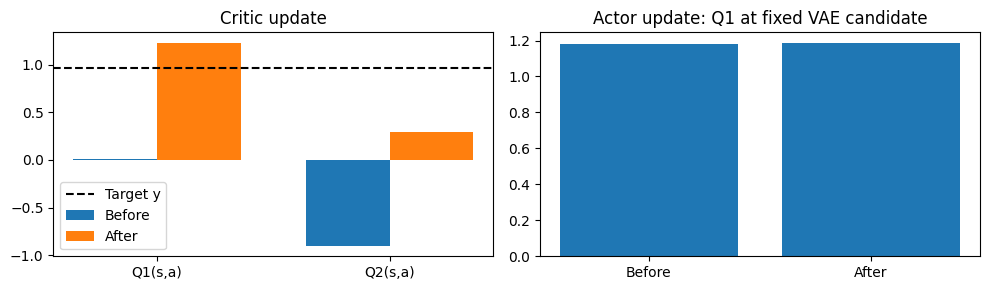

In [8]:
fixed_candidate = candidate.detach()
before_action = agent.actor(states, fixed_candidate)
actor_q_before = agent.critic.q1(states, before_action)
actor_loss = -actor_q_before.mean()
agent.actor_optimizer.zero_grad()
actor_loss.backward()
agent.actor_optimizer.step()
with torch.no_grad():
    after_action = agent.actor(states, fixed_candidate)
    actor_q_after = agent.critic.q1(states, after_action)
agent._soft_update(agent.critic, agent.critic_target)
agent._soft_update(agent.actor, agent.actor_target)
print("Action before:", before_action.detach().numpy().round(6))
print("Action after: ", after_action.numpy().round(6))
print("Q1 before / after actor step:", actor_q_before.item(), actor_q_after.item())
print("Actor loss before / after:", actor_loss.item(), -actor_q_after.item())
print("Soft update tau:", agent.tau)

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
x = np.arange(2)
axes[0].bar(x - 0.18, q_before, 0.36, label="Before")
axes[0].bar(x + 0.18, q_after, 0.36, label="After")
axes[0].axhline(target_y.item(), color="black", linestyle="--", label="Target y")
axes[0].set(xticks=x, xticklabels=["Q1(s,a)", "Q2(s,a)"], title="Critic update")
axes[0].legend()
axes[1].bar(["Before", "After"], [actor_q_before.item(), actor_q_after.item()])
axes[1].set(title="Actor update: Q1 at fixed VAE candidate")
plt.tight_layout()
plt.show()

## 8. Short training example

The next cell runs 100 BC updates on mixed data to check the training interface.
Its artifacts are separate from the main experiment. Run the full suite with:

```bash
python run_experiments.py --suite all --steps 100000
python make_report.py
```

There are 36 main runs and 15 additional ablation runs. Mixed-data BCQ at Phi=0.05
is shared by both suites. Each run also evaluates new start/goal pairs.

In [9]:
args = build_parser().parse_args([
    "--algo", "bc", "--dataset", "data/mixed.npz", "--seed", "0", "--steps", "100",
    "--eval-episodes", "2", "--probe-size", "32",
    "--results-dir", "results/notebook/runs", "--checkpoint-dir", "results/notebook/checkpoints"
])
demo_run_path = train(args)
demo_run = json.loads(demo_run_path.read_text(encoding="utf-8"))
print("Saved:", demo_run_path)
print(json.dumps(demo_run["history"][-1], indent=2))
print("BC has no critic: q_dataset and q_start are null.")

bc_mixed_seed0_repeat2 | 100/100 | success=0.000 collision=1.000 reward=12.014 steps=13.0 Q=None G0=11.686


Saved: results\notebook\runs\bc_mixed_seed0_repeat2.json
{
  "episodes": 2,
  "success_rate": 0.0,
  "collision_rate": 1.0,
  "average_reward": 12.014403572082522,
  "average_steps": 13.0,
  "discounted_return": 11.6862657974447,
  "discounted_return_std": 0.08388386391496816,
  "q_start": null,
  "q_dataset": null,
  "step": 100
}
BC has no critic: q_dataset and q_start are null.


## 9. Experiment tables and plots

Show the main report when available; otherwise label the smoke-test report explicitly.
Mean and standard deviation are computed across training seeds, not episodes.
Dataset Q and start-state return use different state distributions.
Compare `Q(start)` directly with the measured `G0`.

Report saved to results\smoke_suite\report; unique runs: 51, missing main runs: 0
SMOKE TEST ONLY: 100 training steps, 2 evaluation episodes; not a scientific result


| Dataset | Algorithm | Phi | Seeds | Success | Collision | Reward | Steps | Return |
|---|---|---:|---:|---:|---:|---:|---:|---:|
| easy | BC | None | 3 | 0.333 ± 0.577 | 0.667 ± 0.577 | 34.469 ± 27.066 | 28.500 ± 17.385 | 28.405 ± 19.031 |
| easy | BCQ | 0.05 | 3 | 0.167 ± 0.289 | 0.833 ± 0.289 | 19.475 ± 14.655 | 17.667 ± 7.687 | 17.028 ± 10.851 |
| easy | TD3 | None | 3 | 0.000 ± 0.000 | 1.000 ± 0.000 | 14.619 ± 0.000 | 9.000 ± 0.000 | 14.333 ± 0.000 |
| mixed | BC | None | 3 | 0.000 ± 0.000 | 1.000 ± 0.000 | 16.325 ± 10.719 | 14.833 ± 6.934 | 15.518 ± 9.636 |
| mixed | BCQ | 0.05 | 3 | 0.000 ± 0.000 | 1.000 ± 0.000 | 12.679 ± 0.610 | 11.833 ± 0.289 | 12.359 ± 0.570 |
| mixed | TD3 | None | 3 | 0.000 ± 0.000 | 1.000 ± 0.000 | 14.619 ± 0.000 | 9.000 ± 0.000 | 14.333 ± 0.000 |
| noisy | BC | None | 3 | 0.333 ± 0.577 | 0.667 ± 0.577 | 32.757 ± 26.860 | 47.333 ± 20.064 | 24.520 ± 15.703 |
| noisy | BCQ | 0.05 | 3 | 0.000 ± 0.000 | 1.000 ± 0.000 | 14.125 ± 5.989 | 18.667 ± 3.175 | 13.457 ± 5.445 |
| noisy | TD3 | None | 3 | 0.000 ± 0.000 | 1.000 ± 0.000 | 14.619 ± 0.000 | 9.000 ± 0.000 | 14.333 ± 0.000 |
| small | BC | None | 3 | 0.000 ± 0.000 | 1.000 ± 0.000 | 16.940 ± 5.127 | 14.167 ± 2.082 | 16.274 ± 4.750 |
| small | BCQ | 0.05 | 3 | 0.000 ± 0.000 | 1.000 ± 0.000 | 11.843 ± 1.825 | 12.000 ± 0.500 | 11.567 ± 1.712 |
| small | TD3 | None | 3 | 0.000 ± 0.000 | 1.000 ± 0.000 | 14.619 ± 0.000 | 9.000 ± 0.000 | 14.333 ± 0.000 |


| Dataset | Algorithm | Phi | Seeds | Success | Collision | Reward | Steps | Return |
|---|---|---:|---:|---:|---:|---:|---:|---:|
| easy | BC | None | 3 | 0.000 ± 0.000 | 1.000 ± 0.000 | 22.085 ± 11.923 | 24.500 ± 12.031 | 19.863 ± 10.254 |
| easy | BCQ | 0.05 | 3 | 0.000 ± 0.000 | 1.000 ± 0.000 | 15.044 ± 8.758 | 19.333 ± 8.737 | 13.649 ± 6.728 |
| easy | TD3 | None | 3 | 0.000 ± 0.000 | 1.000 ± 0.000 | 13.360 ± 0.000 | 8.500 ± 0.000 | 13.136 ± 0.000 |
| mixed | BC | None | 3 | 0.000 ± 0.000 | 1.000 ± 0.000 | 17.031 ± 6.079 | 16.333 ± 1.155 | 16.141 ± 5.623 |
| mixed | BCQ | 0.05 | 3 | 0.000 ± 0.000 | 1.000 ± 0.000 | 9.446 ± 0.599 | 11.000 ± 0.500 | 9.320 ± 0.566 |
| mixed | TD3 | None | 3 | 0.000 ± 0.000 | 1.000 ± 0.000 | 13.360 ± 0.000 | 8.500 ± 0.000 | 13.136 ± 0.000 |
| noisy | BC | None | 3 | 0.000 ± 0.000 | 1.000 ± 0.000 | 11.664 ± 3.378 | 29.167 ± 2.887 | 10.930 ± 3.021 |
| noisy | BCQ | 0.05 | 3 | 0.000 ± 0.000 | 1.000 ± 0.000 | 12.149 ± 5.313 | 17.333 ± 2.466 | 11.691 ± 4.868 |
| noisy | TD3 | None | 3 | 0.000 ± 0.000 | 1.000 ± 0.000 | 13.360 ± 0.000 | 8.500 ± 0.000 | 13.136 ± 0.000 |
| small | BC | None | 3 | 0.000 ± 0.000 | 1.000 ± 0.000 | 13.962 ± 5.875 | 12.667 ± 1.756 | 13.536 ± 5.499 |
| small | BCQ | 0.05 | 3 | 0.000 ± 0.000 | 1.000 ± 0.000 | 14.995 ± 9.571 | 17.500 ± 11.258 | 13.617 ± 7.404 |
| small | TD3 | None | 3 | 0.000 ± 0.000 | 1.000 ± 0.000 | 13.360 ± 0.000 | 8.500 ± 0.000 | 13.136 ± 0.000 |


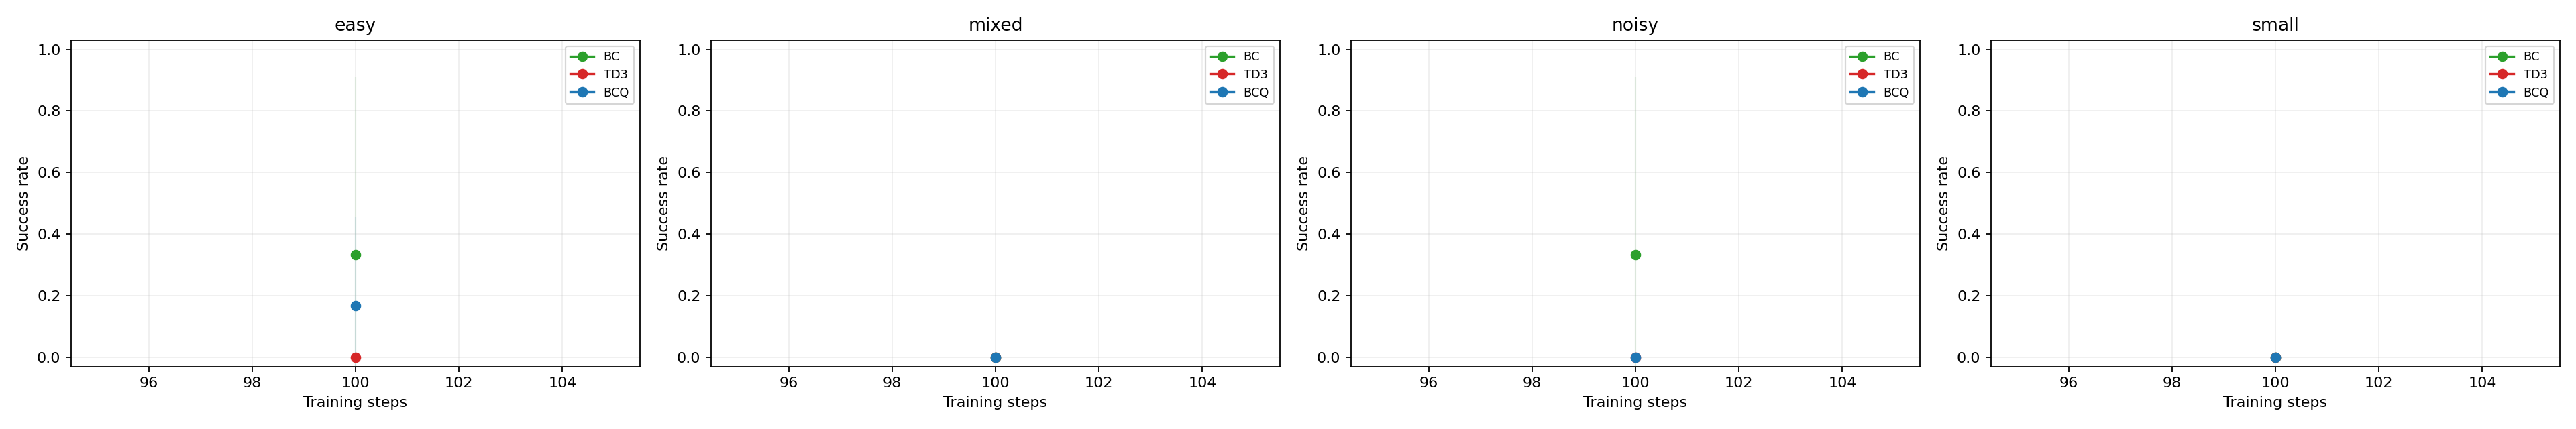

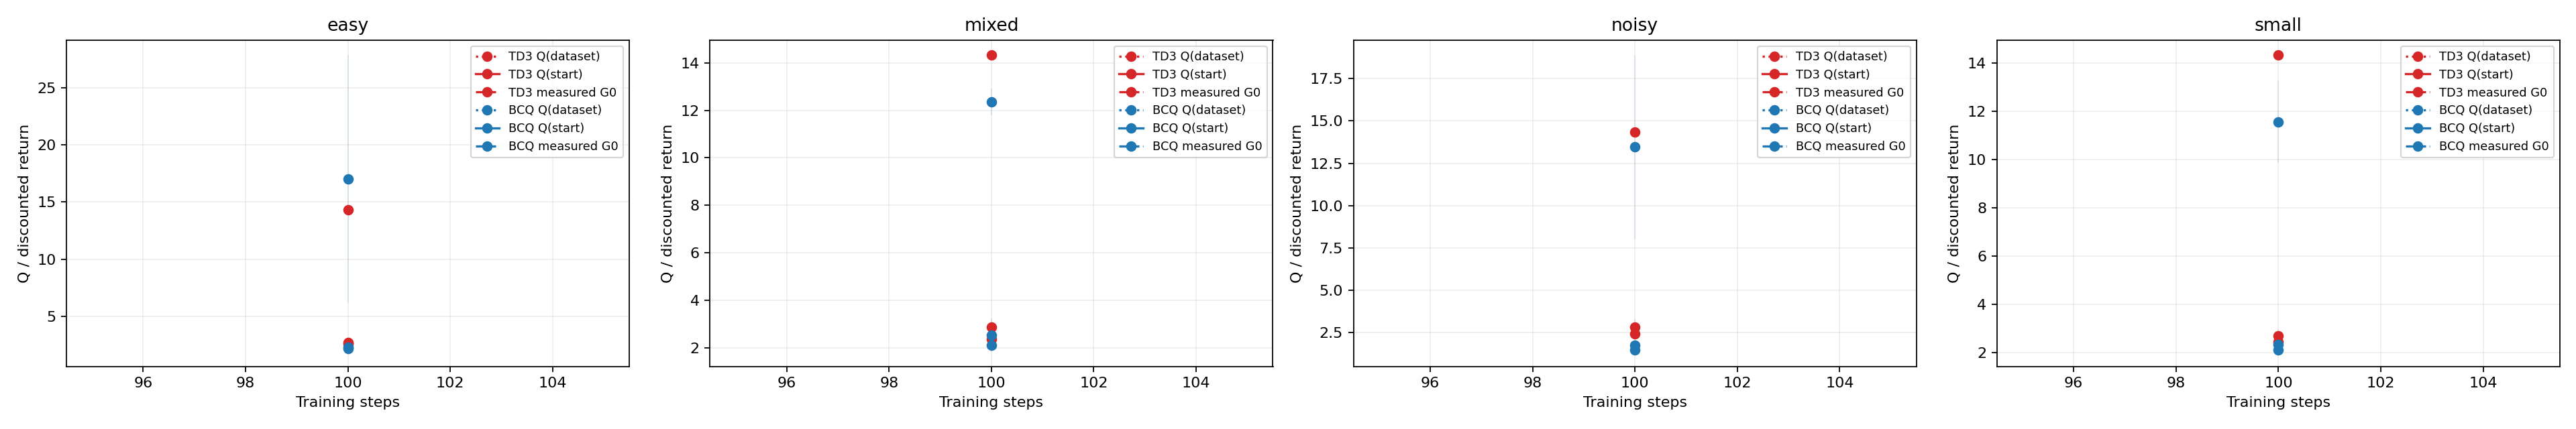

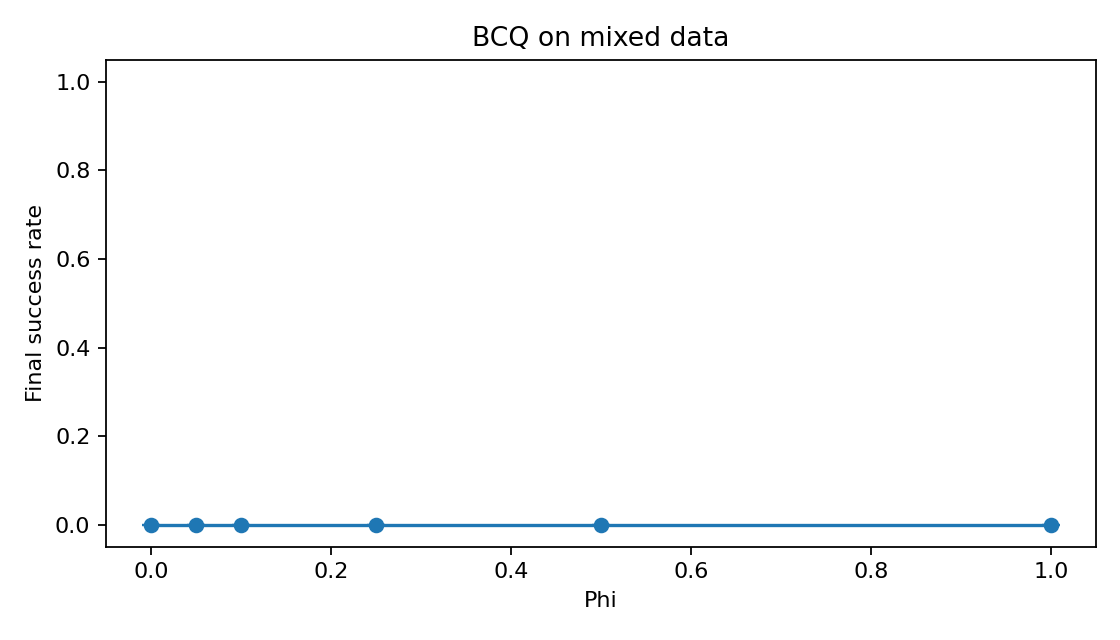

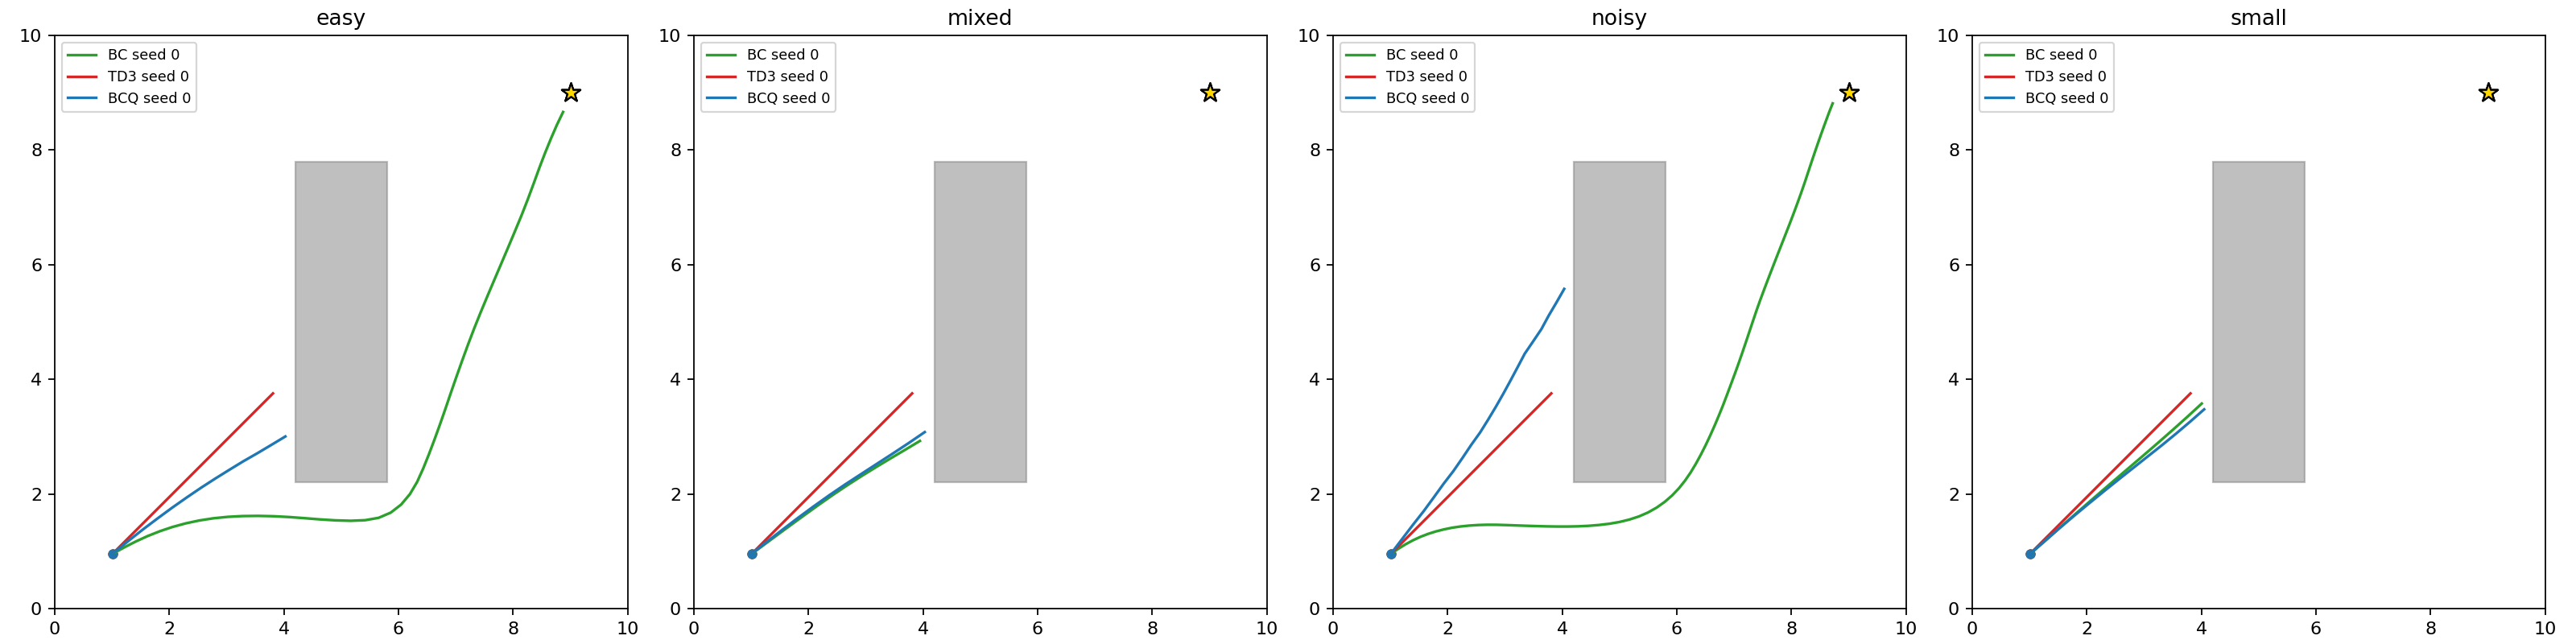

In [10]:
from make_report import make_report

main_runs = Path("results/runs")
smoke_runs = Path("results/smoke_suite/runs")
completed = lambda directory: any(
    json.loads(p.read_text(encoding="utf-8")).get("status") == "completed"
    for p in directory.glob("*.json")
) if directory.exists() else False
if completed(main_runs):
    report_dir = make_report(main_runs, Path("results/report"))
    print("Main experiment report")
elif completed(smoke_runs):
    report_dir = make_report(smoke_runs, Path("results/smoke_suite/report"))
    print("SMOKE TEST ONLY: 100 training steps, 2 evaluation episodes; not a scientific result")
else:
    report_dir = None
    print("Run run_experiments.py to obtain result tables and learning curves.")
if report_dir is not None:
    display(Markdown((report_dir / "results_table.md").read_text(encoding="utf-8")))
    display(Markdown((report_dir / "generalization_table.md").read_text(encoding="utf-8")))
    for name in ("success_curves.png", "q_curves.png", "phi_ablation.png", "trajectories.png"):
        path = report_dir / name
        if path.exists():
            display(Image(filename=str(path)))

## 10. Saved BCQ policy animation

Use the historical checkpoint to illustrate navigation. It is excluded from the new
BC/TD3/BCQ comparison. If it is missing, train a short demo model and label it explicitly.

In [11]:
from demo import rollout

visual_agent = make_agent("bcq", device="cpu")
if MODEL_PATH.exists():
    visual_agent.load(MODEL_PATH)
    print("Historical demonstration checkpoint:", MODEL_PATH)
else:
    print("No historical checkpoint; training 100 demonstration updates")
    for _ in range(100):
        visual_agent.train(dataset.sample(256))
positions, total_reward, info = rollout(visual_agent, seed=4042)
print("Reward:", round(total_reward, 3), "Success:", info["success"], "Collision:", info["collision"])

fig, ax = plt.subplots(figsize=(5, 5))
for x0, y0, x1, y1 in OBSTACLES:
    ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, color="gray", alpha=0.6))
ax.scatter(9, 9, marker="*", s=180, color="gold", edgecolor="black")
ax.set(xlim=(0, 10), ylim=(0, 10), aspect="equal", title="BCQ demonstration")
line, = ax.plot([], [], color="tab:blue")
marker, = ax.plot([], [], "o", color="tab:red")

def update(frame):
    # Draw the current trajectory.
    line.set_data(positions[:frame + 1, 0], positions[:frame + 1, 1])
    marker.set_data([positions[frame, 0]], [positions[frame, 1]])
    return line, marker

animation = FuncAnimation(fig, update, frames=len(positions), interval=100, blit=True)
html = animation.to_jshtml()
plt.close(fig)
display(HTML(html))

Historical demonstration checkpoint: C:\Users\ksvibe\RL_Project\checkpoints\bcq_final.pt
Reward: 64.383 Success: True Collision: False


## Interpretation

Increasing Q alone does not establish policy improvement. Check success, collisions
and measured discounted return. Returns stop at the 120-step horizon, while dataset
timeouts retain Bellman bootstrapping. This can also cause Q/return differences.
Generalization uses new start/goal pairs near the original regions, not new maps.